# Segmentasi Spasial E-Commerce Brasil Menggunakan Apache Spark K-Means Clustering Berbasis Pola Konsumsi dan Logistik Regional
### Studi Kasus: Olist Brazilian E-Commerce Public Dataset

**Lampiran Teknis Laporan Akhir Proyek — Mata Kuliah Teknologi Big Data**
Program Studi Teknologi Rekayasa Perangkat Lunak, Sekolah Vokasi IPB University, 2026

**Kelompok 13 (Kelas B1)**

| No. | Nama | NIM |
|---|---|---|
| 1 | Nur'Afia Avanza | J0403241008 |
| 2 | Josua Abrianto Harianja | J0403241062 |
| 3 | Ben Azaria | J0403241135 |
| 4 | Zafira Ryani Putri | J0403241139 |

**Sumber data:** [Kaggle — Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (salinan 9 berkas CSV tersedia di [github.com/Lehonci/olist](https://github.com/Lehonci/olist), folder `data/`).

**Cara menjalankan.** Notebook ini mandiri: data diunduh otomatis dari GitHub bila folder `data/` belum ada, dan seluruh pemrosesan berjalan pada Spark mode lokal (`local[*]`) tanpa Kafka maupun PostgreSQL. Jalankan sel dari atas ke bawah (*Run All*). Dapat dijalankan di komputer lokal atau Google Colab. Logika SQL dan model pada notebook ini sama dengan `eda_spark.py` pada repositori proyek, sehingga hasilnya dapat dibandingkan langsung dengan laporan.

**Daftar isi**
1. Pendahuluan dan penyiapan environment
2. Ingesti dan pemeriksaan skema multi-dataset
3. Pembersihan data dan agregasi tingkat pesanan (pra-agregasi anti join fan-out)
4. Rekayasa fitur spasial 27 negara bagian
5. Penentuan K: evaluasi Elbow Method dan Silhouette Score (K = 2–8)
6. Profiling dan interpretasi klaster wilayah (RQ2 dan RQ4)
7. Analisis kategori produk dominan per klaster (RQ3)
8. Implikasi manajerial, rekomendasi, dan ekspor hasil

---
# BAB 1. PENDAHULUAN DAN PENYIAPAN ENVIRONMENT

## 1.1 Latar Belakang

Brasil memiliki wilayah yang sangat luas dengan sebaran infrastruktur dan penduduk yang timpang. Negara bagian di wilayah Tenggara dan Selatan (misalnya São Paulo, Rio de Janeiro, Minas Gerais) memiliki kepadatan penjual, pusat distribusi, dan jaringan logistik yang jauh lebih baik daripada wilayah Utara dan Timur Laut. Pada platform *marketplace* seperti Olist, kesenjangan ini tercermin pada **disparitas ongkos kirim (*freight value*)**, durasi pengiriman, dan pola belanja pelanggan antarwilayah.

Apabila strategi pemasaran dan distribusi diperlakukan seragam (*one-size-fits-all*), promosi menjadi kurang efektif, alokasi stok tidak sesuai dengan preferensi lokal, dan beban logistik wilayah perifer tetap tinggi. Diperlukan segmentasi wilayah yang berbasis data.

## 1.2 Rumusan Masalah dan Tujuan

Segmentasi dilakukan secara **tanpa label (*unsupervised learning*)** karena tidak ada kelas wilayah yang diketahui sebelumnya. Algoritma yang dipakai adalah **K-Means Clustering** pada Apache Spark MLlib. Pertanyaan penelitian:

| Kode | Pertanyaan |
|---|---|
| RQ1 | Wilayah (kota dan negara bagian) mana yang memiliki jumlah pelanggan dan volume transaksi tertinggi? |
| RQ2 | Bagaimana negara bagian dapat dikelompokkan secara optimal berdasarkan pola pembelian dan karakteristik wilayahnya? |
| RQ3 | Kategori produk apa yang paling banyak dibeli pada setiap kelompok wilayah? |
| RQ4 | Apakah terdapat perbedaan pola konsumsi yang nyata antara wilayah berkepadatan tinggi, menengah, dan rendah? |

## 1.3 Penyiapan Environment

Sel berikut memasang PySpark bila belum tersedia (pada Colab Java sudah tersedia; pada komputer lokal pastikan Java 17 atau lebih baru terpasang), mengimpor pustaka, dan membuat `SparkSession` lokal dengan memori driver 4 GB.

In [25]:
import os, sys, math, subprocess, urllib.request, warnings
warnings.filterwarnings("ignore")

try:
    import pyspark
except ImportError:                      # pemasangan otomatis (mis. pada Google Colab)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark"])
    import pyspark

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

try:
    display
except NameError:                        # bila dijalankan di luar Jupyter
    display = print

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", font_scale=0.95)

spark = (
    SparkSession.builder.master("local[*]")
    .appName("Olist_Segmentasi_Spasial_KMeans")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.ansi.enabled", "false")      # perilaku SQL sama dengan eda_spark.py
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("PySpark :", pyspark.__version__)
print("Spark   :", spark.version)

PySpark : 4.0.5
Spark   : 4.0.5


---
# BAB 2. INGESTI DAN PEMERIKSAAN SKEMA MULTI-DATASET

Pada arsitektur lengkap proyek, data mengalir dari CSV → Apache Kafka → PostgreSQL (*staging*) → Spark. Notebook ini melewati Kafka dan PostgreSQL dan membaca CSV langsung ke Spark agar mudah direproduksi. Seluruh kolom awalnya dibaca sebagai teks (sama seperti lapisan *staging* yang bertipe `VARCHAR`), lalu kolom numerik di-*cast* secara eksplisit sehingga tipe data tidak bergantung pada tebakan *schema inference*.

**Tabel yang dimuat (9 berkas, 52 atribut):** tujuh tabel utama (`customers`, `orders`, `order_items`, `payments`, `reviews`, `products`, `category_translation`) ditambah `sellers` (jumlah penjual per wilayah) dan `geolocation` (koordinat pusat tiap negara bagian untuk peta).

In [26]:
GITHUB_RAW = "https://raw.githubusercontent.com/Lehonci/olist/main/data/"
DATA_DIR = os.getenv("OLIST_DATA_DIR", "data")

FILES = {                                   # nama view Spark -> nama berkas CSV
    "customers":            "olist_customers_dataset.csv",
    "orders":               "olist_orders_dataset.csv",
    "order_items":          "olist_order_items_dataset.csv",
    "payments":             "olist_order_payments_dataset.csv",
    "reviews":              "olist_order_reviews_dataset.csv",
    "products":             "olist_products_dataset.csv",
    "sellers":              "olist_sellers_dataset.csv",
    "geolocation":          "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

# Jumlah baris resmi dataset (untuk validasi pembacaan)
EXPECTED_ROWS = {
    "customers": 99441, "orders": 99441, "order_items": 112650, "payments": 103886,
    "reviews": 99224, "products": 32951, "sellers": 3095, "geolocation": 1000163,
    "category_translation": 71,
}

# Kolom numerik yang di-cast eksplisit (kolom lain tetap teks, sama seperti lapisan staging)
CASTS = {
    "order_items": {"order_item_id": "int", "price": "double", "freight_value": "double"},
    "payments":    {"payment_sequential": "int", "payment_installments": "int", "payment_value": "double"},
    "reviews":     {"review_score": "int"},
    "geolocation": {"geolocation_lat": "double", "geolocation_lng": "double"},
}

def ensure_data():
    """Mengunduh berkas CSV dari GitHub bila belum ada di folder data/."""
    os.makedirs(DATA_DIR, exist_ok=True)
    for fname in FILES.values():
        path = os.path.join(DATA_DIR, fname)
        if not os.path.isfile(path):
            print(f"Mengunduh {fname} ...")
            urllib.request.urlretrieve(GITHUB_RAW + fname, path)
    print("Seluruh berkas data tersedia di:", os.path.abspath(DATA_DIR))

def load_table(view, fname):
    df = spark.read.csv(
        os.path.join(DATA_DIR, fname),
        header=True, inferSchema=False, multiLine=True, quote='"', escape='"', encoding="UTF-8",
    )
    df = df.toDF(*[c.replace("\ufeff", "").strip() for c in df.columns])   # buang BOM bila ada
    for col, typ in CASTS.get(view, {}).items():
        df = df.withColumn(col, F.col(col).cast(typ))
    df.createOrReplaceTempView(view)
    return df

ensure_data()
tables = {view: load_table(view, fname) for view, fname in FILES.items()}
print("Sembilan tabel terdaftar sebagai Spark view:", ", ".join(tables))

Seluruh berkas data tersedia di: /content/data
Sembilan tabel terdaftar sebagai Spark view: customers, orders, order_items, payments, reviews, products, sellers, geolocation, category_translation


## 2.1 Validasi Data Mentah

Setiap tabel dihitung jumlah baris dan atributnya, lalu dibandingkan dengan jumlah baris resmi dataset. Hasil penjumlahan seluruh tabel seharusnya **1.550.922 baris** dengan **52 atribut**.

In [27]:
rows = []
for view, df in tables.items():
    n = df.count()
    rows.append({"tabel": view, "baris": n, "atribut": len(df.columns),
                 "baris_resmi": EXPECTED_ROWS[view], "sesuai": "ya" if n == EXPECTED_ROWS[view] else "TIDAK"})
df_validasi = pd.DataFrame(rows)
total = pd.DataFrame([{"tabel": "TOTAL", "baris": df_validasi["baris"].sum(), "atribut": df_validasi["atribut"].sum(),
                       "baris_resmi": sum(EXPECTED_ROWS.values()), "sesuai": ""}])
display(pd.concat([df_validasi, total], ignore_index=True).style.format({"baris": "{:,.0f}", "baris_resmi": "{:,.0f}"}))
assert (df_validasi["sesuai"] == "ya").all(), "Ada tabel yang jumlah barisnya berbeda dari dataset resmi."

,tabel,baris,atribut,baris_resmi,sesuai
0,customers,"99,441",5,"99,441",ya
1,orders,"99,441",8,"99,441",ya
2,order_items,"112,650",7,"112,650",ya
3,payments,"103,886",5,"103,886",ya
4,reviews,"99,224",7,"99,224",ya
5,products,"32,951",9,"32,951",ya
6,sellers,"3,095",4,"3,095",ya
7,geolocation,"1,000,163",5,"1,000,163",ya
8,category_translation,71,2,71,ya
9,TOTAL,"1,550,922",52,"1,550,922",


In [28]:
# Skema tujuh tabel utama
for view in ["customers", "orders", "order_items", "payments", "reviews", "products", "category_translation"]:
    print(f"\n=== {view} ===")
    tables[view].printSchema()


=== customers ===
root
 |-- customer_id: string (nullable = true)
 |-- customer_unique_id: string (nullable = true)
 |-- customer_zip_code_prefix: string (nullable = true)
 |-- customer_city: string (nullable = true)
 |-- customer_state: string (nullable = true)


=== orders ===
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: string (nullable = true)
 |-- order_approved_at: string (nullable = true)
 |-- order_delivered_carrier_date: string (nullable = true)
 |-- order_delivered_customer_date: string (nullable = true)
 |-- order_estimated_delivery_date: string (nullable = true)


=== order_items ===
root
 |-- order_id: string (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: string (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_val

## 2.2 Relasi Antartabel

Relasi bersifat *one-to-many* (satu pesanan dapat memiliki banyak item, banyak cicilan pembayaran, dan lebih dari satu ulasan). Inilah sumber risiko **duplikasi nilai (*join fan-out*)** yang ditangani pada Bab 3.

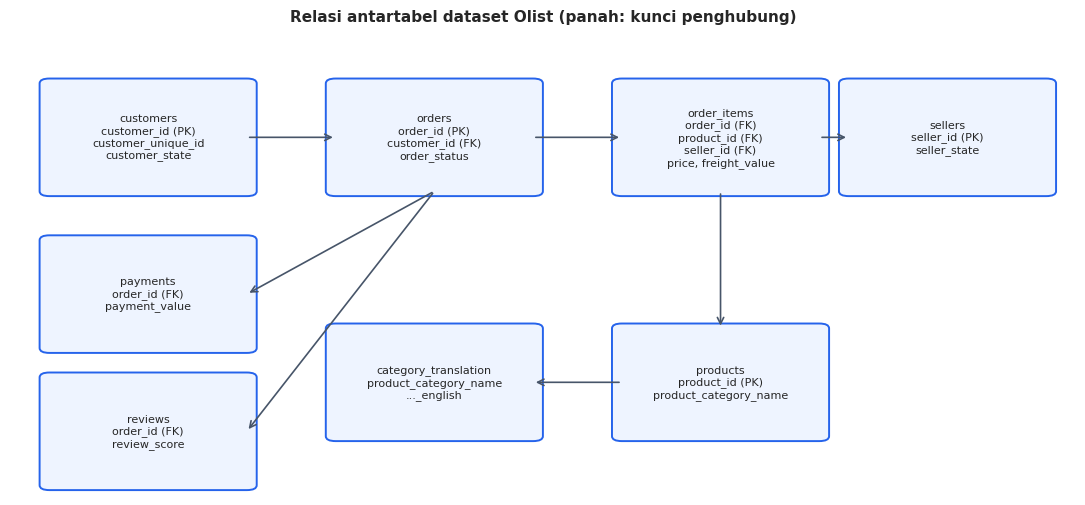

In [29]:
from matplotlib.patches import FancyBboxPatch

boxes = {                      # nama: (x, y, isi)
    "customers":   (0.04, 0.62, "customers\ncustomer_id (PK)\ncustomer_unique_id\ncustomer_state"),
    "orders":      (0.33, 0.62, "orders\norder_id (PK)\ncustomer_id (FK)\norder_status"),
    "order_items": (0.62, 0.62, "order_items\norder_id (FK)\nproduct_id (FK)\nseller_id (FK)\nprice, freight_value"),
    "products":    (0.62, 0.12, "products\nproduct_id (PK)\nproduct_category_name"),
    "category_translation": (0.33, 0.12, "category_translation\nproduct_category_name\n..._english"),
    "payments":    (0.04, 0.30, "payments\norder_id (FK)\npayment_value"),
    "reviews":     (0.04, 0.02, "reviews\norder_id (FK)\nreview_score"),
    "sellers":     (0.85, 0.62, "sellers\nseller_id (PK)\nseller_state"),
}
W, H = 0.20, 0.22
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 1.08); ax.set_ylim(0, 0.95); ax.axis("off")
for name, (x, y, text) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.01", fc="#EEF4FF", ec="#2563EB", lw=1.4))
    ax.text(x + W / 2, y + H / 2, text, ha="center", va="center", fontsize=8)

def center(n, side):
    x, y, _ = boxes[n]
    return {"r": (x + W, y + H / 2), "l": (x, y + H / 2), "t": (x + W / 2, y + H), "b": (x + W / 2, y)}[side]

links = [("customers", "r", "orders", "l"), ("orders", "r", "order_items", "l"),
         ("order_items", "b", "products", "t"), ("products", "l", "category_translation", "r"),
         ("order_items", "r", "sellers", "l"), ("orders", "b", "payments", "r"), ("orders", "b", "reviews", "r")]
for a, sa, b, sb in links:
    (x1, y1), (x2, y2) = center(a, sa), center(b, sb)
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.2))
ax.set_title("Relasi antartabel dataset Olist (panah: kunci penghubung)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

---
# BAB 3. PEMBERSIHAN DATA DAN AGREGASI TINGKAT PESANAN (PRE-JOIN DEDUPLICATION)

## 3.1 Aturan Bisnis

1. **Hanya pesanan berstatus `delivered`** yang dianalisis, karena hanya pesanan yang sampai ke pelanggan yang mencerminkan pola belanja dan logistik sebenarnya.
2. **Pelanggan unik dihitung dengan `COUNT(DISTINCT customer_unique_id)`**, bukan `customer_id`. Pada Olist, `customer_id` dibuat baru untuk setiap pesanan sehingga pelanggan yang sama dapat muncul berkali-kali.
3. **Pembayaran, item/ongkir, dan ulasan diagregasi per `order_id` terlebih dahulu** (melalui CTE), baru di-*join*. Tanpa langkah ini, pesanan dengan banyak item atau banyak cicilan akan menggandakan nilai pendapatan.

## 3.2 Distribusi Status Pesanan

,order_status,total_orders,pct_orders
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


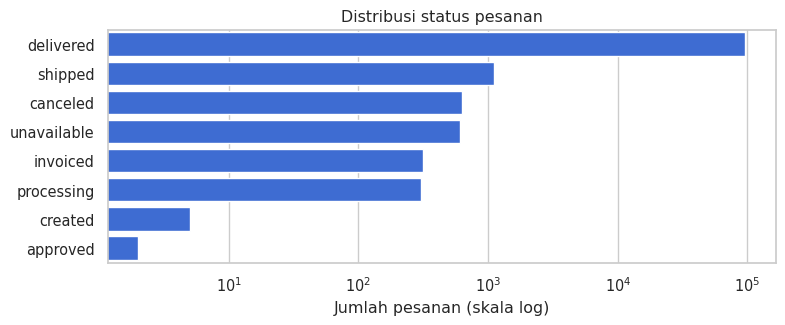

In [30]:
df_status = spark.sql("""
    WITH total_ord AS (SELECT COUNT(order_id) AS all_orders FROM orders)
    SELECT o.order_status,
           COUNT(o.order_id) AS total_orders,
           ROUND(COUNT(o.order_id) * 100.0 / MAX(t.all_orders), 2) AS pct_orders
    FROM orders o CROSS JOIN total_ord t
    GROUP BY o.order_status
    ORDER BY total_orders DESC
""").toPandas()
display(df_status)

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.barplot(data=df_status, y="order_status", x="total_orders", color="#2563EB", ax=ax)
ax.set_xscale("log"); ax.set_xlabel("Jumlah pesanan (skala log)"); ax.set_ylabel("")
ax.set_title("Distribusi status pesanan")
plt.tight_layout(); plt.show()

## 3.3 Demonstrasi Masalah *Join Fan-Out*

Sel berikut membandingkan total pendapatan pesanan `delivered` dari dua cara: (a) *join* langsung `orders → order_items → payments` tanpa pra-agregasi, dan (b) pra-agregasi pembayaran per `order_id` dengan CTE. Cara (a) menggandakan nilai pembayaran untuk pesanan yang memiliki lebih dari satu item.

In [31]:
naif = spark.sql("""
    SELECT COUNT(*) AS baris_setelah_join,
           ROUND(SUM(p.payment_value), 2) AS pendapatan
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN payments p     ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
""").toPandas().assign(metode="(a) Join langsung (salah, terduplikasi)")

benar = spark.sql("""
    WITH order_pay AS (
        SELECT order_id, SUM(payment_value) AS order_payment_value FROM payments GROUP BY order_id
    )
    SELECT COUNT(*) AS baris_setelah_join,
           ROUND(SUM(op.order_payment_value), 2) AS pendapatan
    FROM orders o
    JOIN order_pay op ON o.order_id = op.order_id
    WHERE o.order_status = 'delivered'
""").toPandas().assign(metode="(b) Pra-agregasi CTE (benar)")

cmp_fanout = pd.concat([naif, benar])[["metode", "baris_setelah_join", "pendapatan"]]
inflasi = cmp_fanout.iloc[0]["pendapatan"] / cmp_fanout.iloc[1]["pendapatan"] - 1
display(cmp_fanout.style.format({"baris_setelah_join": "{:,.0f}", "pendapatan": "R$ {:,.2f}"}))
print(f"Pendapatan terlalu besar {inflasi:.2%} bila pra-agregasi tidak dilakukan.")

,metode,baris_setelah_join,pendapatan
0,"(a) Join langsung (salah, terduplikasi)","115,035","R$ 19,776,160.44"
0,(b) Pra-agregasi CTE (benar),"96,477","R$ 15,422,461.77"


Pendapatan terlalu besar 28.23% bila pra-agregasi tidak dilakukan.


## 3.4 Ringkasan KPI Nasional

Seluruh metrik dihitung dengan pra-agregasi per pesanan (CTE `order_pay`, `order_itm`, `order_rev`). Nilai acuan laporan: **96.096 pelanggan unik**, **96.478 pesanan *delivered*** (97,02% dari 99.441 pesanan), 27 negara bagian.

In [8]:
df_kpi = spark.sql("""
    WITH order_pay AS (
        SELECT order_id, SUM(payment_value) AS order_payment_value FROM payments GROUP BY order_id
    ),
    order_itm AS (
        SELECT order_id, AVG(freight_value) AS avg_order_freight FROM order_items GROUP BY order_id
    ),
    order_rev AS (
        SELECT order_id, AVG(CAST(review_score AS DOUBLE)) AS avg_order_review FROM reviews GROUP BY order_id
    )
    SELECT
        CAST(COUNT(DISTINCT c.customer_unique_id) AS LONG) AS total_unique_customers,
        CAST(COUNT(DISTINCT o.order_id) AS LONG) AS total_orders,
        CAST(COUNT(DISTINCT CASE WHEN o.order_status = 'delivered' THEN o.order_id END) AS LONG) AS total_delivered_orders,
        ROUND(SUM(CASE WHEN o.order_status = 'delivered' THEN op.order_payment_value ELSE 0.0 END), 2) AS total_revenue,
        ROUND(AVG(CASE WHEN o.order_status = 'delivered' THEN op.order_payment_value END), 2) AS avg_order_value,
        ROUND(AVG(CASE WHEN o.order_status = 'delivered' THEN oi.avg_order_freight END), 2) AS avg_freight_value,
        ROUND(AVG(orv.avg_order_review), 2) AS avg_review_score,
        CAST(COUNT(DISTINCT c.customer_state) AS INT) AS total_states,
        CAST(COUNT(DISTINCT c.customer_city) AS INT) AS total_cities,
        (SELECT CAST(COUNT(DISTINCT seller_id) AS INT) FROM sellers) AS total_sellers,
        (SELECT CAST(COUNT(DISTINCT product_id) AS INT) FROM products) AS total_products
    FROM customers c
    LEFT JOIN orders o     ON c.customer_id = o.customer_id
    LEFT JOIN order_pay op ON o.order_id = op.order_id
    LEFT JOIN order_itm oi ON o.order_id = oi.order_id
    LEFT JOIN order_rev orv ON o.order_id = orv.order_id
""").toPandas()
display(df_kpi.T.rename(columns={0: "nilai"}))

kpi = df_kpi.iloc[0]
assert kpi["total_unique_customers"] == 96096, "Pelanggan unik berbeda dari nilai acuan laporan"
assert kpi["total_delivered_orders"] == 96478, "Pesanan delivered berbeda dari nilai acuan laporan"
print("Validasi KPI: pelanggan unik 96.096 dan pesanan delivered 96.478 sesuai laporan.")

,nilai
total_unique_customers,"96,096.0000"
total_orders,"99,441.0000"
total_delivered_orders,"96,478.0000"
total_revenue,"15,422,461.7700"
avg_order_value,159.8600
avg_freight_value,20.1500
avg_review_score,4.0900
total_states,27.0000
total_cities,"4,119.0000"
total_sellers,"3,095.0000"


Validasi KPI: pelanggan unik 96.096 dan pesanan delivered 96.478 sesuai laporan.


## 3.5 RQ1 — Kota dengan Pelanggan dan Transaksi Tertinggi

,customer_city,customer_state,total_unique_customers,total_orders,total_revenue,avg_order_value,avg_freight_value
0,sao paulo,SP,14984,15045,"2,108,162.2200",140.1200,14.4400
1,rio de janeiro,RJ,6620,6601,"1,111,872.3200",168.4400,20.7800
2,belo horizonte,MG,2672,2697,"406,050.8700",150.5600,19.5800
3,brasilia,DF,2069,2071,"345,221.8700",166.6900,21.3700
4,curitiba,PR,1465,1489,"238,582.2600",160.2300,18.9700
5,campinas,SP,1398,1406,"209,028.9700",148.6700,15.1400
6,porto alegre,RS,1326,1342,"214,861.8300",160.1100,20.7900
7,salvador,BA,1209,1188,"207,790.8900",174.9100,25.3400
8,guarulhos,SP,1153,1144,"157,750.0400",137.8900,14.4100
9,sao bernardo do campo,SP,908,911,"116,785.2100",128.1900,13.8200


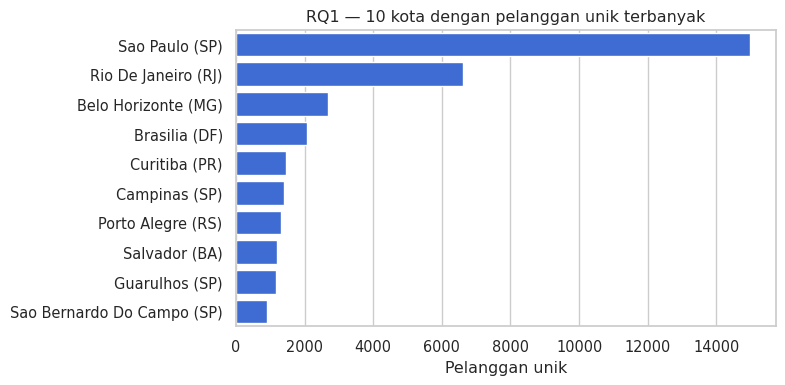

In [9]:
df_cities = spark.sql("""
    WITH order_pay AS (
        SELECT order_id, SUM(payment_value) AS order_payment_value FROM payments GROUP BY order_id
    ),
    order_itm AS (
        SELECT order_id, AVG(freight_value) AS avg_item_freight FROM order_items GROUP BY order_id
    )
    SELECT c.customer_city, c.customer_state,
           COUNT(DISTINCT c.customer_unique_id) AS total_unique_customers,
           COUNT(DISTINCT o.order_id) AS total_orders,
           ROUND(COALESCE(SUM(op.order_payment_value), 0.0), 2) AS total_revenue,
           ROUND(COALESCE(AVG(op.order_payment_value), 0.0), 2) AS avg_order_value,
           ROUND(COALESCE(AVG(oi.avg_item_freight), 0.0), 2) AS avg_freight_value
    FROM customers c
    LEFT JOIN orders o ON c.customer_id = o.customer_id AND o.order_status = 'delivered'
    LEFT JOIN order_pay op ON o.order_id = op.order_id
    LEFT JOIN order_itm oi ON o.order_id = oi.order_id
    GROUP BY c.customer_city, c.customer_state
    ORDER BY total_unique_customers DESC
    LIMIT 25
""").toPandas()
display(df_cities.head(10))

top10 = df_cities.head(10).assign(kota=lambda d: d.customer_city.str.title() + " (" + d.customer_state + ")")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=top10, y="kota", x="total_unique_customers", color="#2563EB", ax=ax)
ax.set_xlabel("Pelanggan unik"); ax.set_ylabel(""); ax.set_title("RQ1 — 10 kota dengan pelanggan unik terbanyak")
plt.tight_layout(); plt.show()

---
# BAB 4. REKAYASA FITUR SPASIAL 27 NEGARA BAGIAN BRASIL

## 4.1 Matriks Fitur Wilayah

Setiap negara bagian (`customer_state`) menjadi satu observasi (27 baris). Tujuh fitur yang dipakai untuk pengelompokan:

| No. | Fitur | Makna |
|---|---|---|
| 1 | `total_customers` | Jumlah pelanggan unik |
| 2 | `total_orders` | Total pesanan berstatus *delivered* |
| 3 | `total_revenue` | Akumulasi nilai pembayaran (R$) |
| 4 | `avg_order_value` | Rata-rata nilai belanja per pesanan (*ticket size*) |
| 5 | `total_items` | Total item fisik yang dibeli |
| 6 | `avg_freight_value` | Rata-rata ongkos kirim |
| 7 | `avg_review_score` | Rata-rata skor kepuasan ulasan (1–5) |

Kolom tambahan (`avg_items_per_order`, `freight_to_price_pct`, `avg_delivery_days`, `lat`, `lng`) dihitung untuk **profiling dan peta**, tetapi **tidak ikut** dalam pemodelan K-Means. Pra-agregasi CTE per `order_id` tetap diterapkan agar tidak terjadi *join fan-out*.

In [10]:
df_state_features = spark.sql("""
    WITH order_pay AS (
        SELECT order_id, SUM(payment_value) AS order_payment_value
        FROM payments GROUP BY order_id
    ),
    order_itm AS (
        SELECT order_id,
               COUNT(order_item_id) AS item_count,
               AVG(freight_value)   AS avg_item_freight,
               SUM(freight_value)   AS total_order_freight,
               SUM(price)           AS total_order_price
        FROM order_items GROUP BY order_id
    ),
    order_rev AS (
        SELECT order_id, AVG(CAST(review_score AS DOUBLE)) AS avg_order_review
        FROM reviews GROUP BY order_id
    ),
    state_geo AS (
        SELECT geolocation_state AS state_code,
               ROUND(AVG(geolocation_lat), 4) AS lat,
               ROUND(AVG(geolocation_lng), 4) AS lng
        FROM geolocation
        WHERE geolocation_lat BETWEEN -35.0 AND 6.0
          AND geolocation_lng BETWEEN -75.0 AND -30.0
        GROUP BY geolocation_state
    )
    SELECT
        c.customer_state,
        CAST(COUNT(DISTINCT c.customer_unique_id) AS DOUBLE) AS total_customers,
        CAST(COUNT(DISTINCT o.order_id) AS DOUBLE) AS total_orders,
        CAST(COALESCE(SUM(op.order_payment_value), 0.0) AS DOUBLE) AS total_revenue,
        CAST(COALESCE(AVG(op.order_payment_value), 0.0) AS DOUBLE) AS avg_order_value,
        CAST(COALESCE(SUM(oi.item_count), 0.0) AS DOUBLE) AS total_items,
        CAST(COALESCE(AVG(oi.avg_item_freight), 0.0) AS DOUBLE) AS avg_freight_value,
        CAST(COALESCE(AVG(orv.avg_order_review), 0.0) AS DOUBLE) AS avg_review_score,
        CAST(COALESCE(AVG(oi.item_count), 0.0) AS DOUBLE) AS avg_items_per_order,
        CAST(COALESCE(SUM(oi.total_order_freight) * 100.0 / NULLIF(SUM(oi.total_order_price), 0.0), 0.0) AS DOUBLE) AS freight_to_price_pct,
        CAST(COALESCE(AVG(DATEDIFF(TO_TIMESTAMP(o.order_delivered_customer_date),
                                   TO_TIMESTAMP(o.order_purchase_timestamp))), 0.0) AS DOUBLE) AS avg_delivery_days,
        g.lat, g.lng
    FROM customers c
    LEFT JOIN orders o ON c.customer_id = o.customer_id AND o.order_status = 'delivered'
    LEFT JOIN order_pay op ON o.order_id = op.order_id
    LEFT JOIN order_itm oi ON o.order_id = oi.order_id
    LEFT JOIN order_rev orv ON o.order_id = orv.order_id
    LEFT JOIN state_geo g ON c.customer_state = g.state_code
    GROUP BY c.customer_state, g.lat, g.lng
    ORDER BY total_revenue DESC
""").na.fill(0.0).coalesce(1).cache()

pdf_state = df_state_features.toPandas()
print("Jumlah observasi (negara bagian):", len(pdf_state))
display(pdf_state.head(10)[["customer_state", "total_customers", "total_orders", "total_revenue",
                            "avg_order_value", "total_items", "avg_freight_value", "avg_review_score"]]
        .style.format({"total_customers": "{:,.0f}", "total_orders": "{:,.0f}", "total_revenue": "{:,.2f}",
                       "avg_order_value": "{:,.2f}", "total_items": "{:,.0f}",
                       "avg_freight_value": "{:,.2f}", "avg_review_score": "{:,.2f}"}))

Jumlah observasi (negara bagian): 27


,customer_state,total_customers,total_orders,total_revenue,avg_order_value,total_items,avg_freight_value,avg_review_score
0,SP,"40,302","40,501","5,770,266.19",142.48,"46,448",15.27,4.25
1,RJ,"12,384","12,350","2,055,690.45",166.45,"14,143",21.10,3.97
2,MG,"11,259","11,354","1,819,277.61",160.23,"12,916",20.80,4.19
3,RS,"5,277","5,345","861,802.40",161.24,"6,134",21.83,4.19
4,PR,"4,882","4,923","781,919.55",158.83,"5,649",20.41,4.24
5,SC,"3,534","3,546","595,208.40",167.85,"4,097",21.80,4.13
6,BA,"3,277","3,256","591,270.60",181.59,"3,683",26.36,3.93
7,DF,"2,075","2,080","346,146.17",166.42,"2,355",21.36,4.13
8,GO,"1,952","1,957","334,294.22",170.82,"2,277",23.03,4.10
9,ES,"1,964","1,995","317,682.65",159.24,"2,225",22.15,4.08


## 4.2 Hubungan Antarfitur

Fitur `total_customers`, `total_orders`, `total_revenue`, dan `total_items` mengukur **skala (volume) pasar**, sedangkan `avg_order_value`, `avg_freight_value`, dan `avg_review_score` menggambarkan **karakter transaksi dan logistik**. Matriks korelasi berikut memperlihatkan bahwa fitur volume saling berkorelasi sangat kuat sehingga pada ruang fitur, perbedaan skala pasar akan sangat memengaruhi jarak antarwilayah.

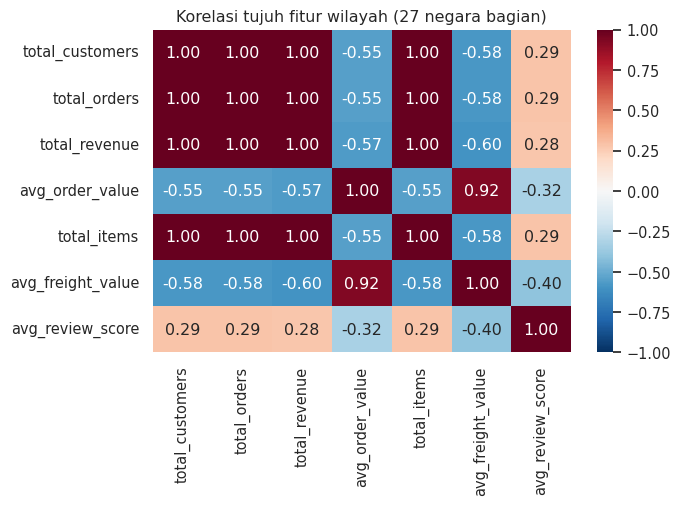

In [11]:
FEATURE_COLS = ["total_customers", "total_orders", "total_revenue", "avg_order_value",
                "total_items", "avg_freight_value", "avg_review_score"]

fig, ax = plt.subplots(figsize=(7, 5.2))
sns.heatmap(pdf_state[FEATURE_COLS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi tujuh fitur wilayah (27 negara bagian)")
plt.tight_layout(); plt.show()

## 4.3 Standardisasi Z-Score

K-Means berbasis jarak Euclidean, sedangkan skala fitur sangat timpang (pendapatan jutaan rupiah Brasil vs skor ulasan satuan). Tanpa standardisasi, fitur berskala besar mendominasi jarak. `StandardScaler(withMean=True, withStd=True)` mengubah setiap fitur menjadi rata-rata 0 dan simpangan baku 1.

In [12]:
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="raw_features")
df_assembled = assembler.transform(df_state_features)

scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled).cache()

# Bukti standardisasi: rata-rata ~0 dan simpangan baku ~1 pada setiap fitur
Z = np.array([r["features"].toArray() for r in df_scaled.select("features").collect()])
display(pd.DataFrame({"fitur": FEATURE_COLS, "rata_rata_z": Z.mean(axis=0), "simpangan_baku_z": Z.std(axis=0, ddof=1)}))

,fitur,rata_rata_z,simpangan_baku_z
0,total_customers,0.0000,1.0000
1,total_orders,-0.0000,1.0000
2,total_revenue,0.0000,1.0000
3,avg_order_value,-0.0000,1.0000
4,total_items,0.0000,1.0000
5,avg_freight_value,-0.0000,1.0000
6,avg_review_score,0.0000,1.0000


---
# BAB 5. HYPERPARAMETER TUNING DAN EVALUASI K-MEANS (K = 2 SAMPAI 8)

## 5.1 Metrik Evaluasi

- **WSSSE (*Within Set Sum of Squared Errors* / inertia)**: jumlah kuadrat jarak titik ke centroid klasternya; semakin kecil semakin kompak. Nilainya selalu turun saat K naik, sehingga dicari **titik siku (*elbow*)**, yaitu K setelah penurunan melandai.
- **Jarak titik siku (Kneedle)**: jarak tegak lurus kurva WSSSE ternormalisasi terhadap garis lurus yang menghubungkan K terkecil dan K terbesar; semakin besar, semakin jelas sikunya.
- **Silhouette Score** (`ClusteringEvaluator`, `squaredEuclidean`): ukuran kohesi dan separasi klaster, bernilai −1 sampai 1.

## 5.2 Aturan Pemilihan K

Dengan hanya 27 observasi dan satu negara bagian (São Paulo) yang sangat ekstrem, Silhouette Score dapat menjadi sangat tinggi ketika model hanya mengisolasi satu *outlier* sebagai klaster tersendiri (klaster *singleton*). Oleh karena itu, kandidat K dibatasi pada nilai yang menghasilkan **minimal dua klaster berisi lebih dari satu negara bagian**, lalu K dipilih dengan nilai **(jarak siku + Silhouette Score) tertinggi**. Pelatihan memakai `seed=1` dan `maxIter=100` seperti pada `eda_spark.py`.

In [13]:
K_RANGE = list(range(2, 9))
SEEDS = (1,)        # sama dengan eda_spark.py; ganti mis. (1, 7, 21, 42, 99) untuk memilih model dengan WSSSE terkecil

evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")

records, models_by_k = [], {}
for k in K_RANGE:
    best = None
    for seed in SEEDS:
        model = KMeans(featuresCol="features", predictionCol="prediction", k=k, seed=seed, maxIter=100).fit(df_scaled)
        cost = float(model.summary.trainingCost)
        if best is None or cost < best[1]:
            best = (model, cost, seed)
    model, wssse, seed_used = best
    models_by_k[k] = model
    preds = model.transform(df_scaled)
    sil = float(evaluator.evaluate(preds))
    sizes = [r["count"] for r in preds.groupBy("prediction").count().collect()]
    records.append({"k": k, "wssse": wssse, "silhouette": sil,
                    "klaster_multi_state": sum(1 for s in sizes if s > 1), "seed": seed_used})

k_min, k_max = K_RANGE[0], K_RANGE[-1]
w_max, w_min = records[0]["wssse"], records[-1]["wssse"]
for i, r in enumerate(records):
    r["penurunan_wssse_pct"] = 0.0 if i == 0 else (records[i-1]["wssse"] - r["wssse"]) * 100 / records[i-1]["wssse"]
    x_norm = (r["k"] - k_min) / (k_max - k_min)
    y_norm = (r["wssse"] - w_min) / (w_max - w_min)
    r["jarak_siku"] = abs(1.0 - x_norm - y_norm) / math.sqrt(2.0)
    r["skor_gabungan"] = r["jarak_siku"] + r["silhouette"]

kandidat = [r for r in records if r["klaster_multi_state"] >= 2]
optimal_k = int(max(kandidat, key=lambda r: r["skor_gabungan"])["k"])
for r in records:
    r["keputusan"] = ("OPTIMAL" if r["k"] == optimal_k
                      else "Hanya mengisolasi outlier" if r["klaster_multi_state"] < 2 else "")

eval_df = pd.DataFrame(records)[["k", "wssse", "penurunan_wssse_pct", "jarak_siku", "silhouette",
                                 "klaster_multi_state", "skor_gabungan", "keputusan"]]
display(eval_df.style.format({"wssse": "{:.4f}", "penurunan_wssse_pct": "{:.2f}",
                              "jarak_siku": "{:.4f}", "silhouette": "{:.4f}", "skor_gabungan": "{:.4f}"})
        .apply(lambda s: ["font-weight: bold; background-color: #DCFCE7" if s["k"] == optimal_k else "" for _ in s], axis=1))
print(f"K optimal terpilih: {optimal_k}")

,k,wssse,penurunan_wssse_pct,jarak_siku,silhouette,klaster_multi_state,skor_gabungan,keputusan
0,2,86.5273,0.00,0.0000,0.8896,1,0.8896,Hanya mengisolasi outlier
1,3,42.9592,50.35,0.3037,0.5675,2,0.8712,OPTIMAL
2,4,29.5565,31.20,0.3155,0.5251,3,0.8406,
3,5,22.5875,23.58,0.2651,0.4586,4,0.7237,
4,6,18.5277,17.97,0.1865,0.4679,4,0.6544,
5,7,16.3881,11.55,0.0893,0.4119,3,0.5012,
6,8,13.4401,17.99,0.0000,0.3979,6,0.3979,


K optimal terpilih: 3


## 5.3 Kurva Elbow dan Silhouette

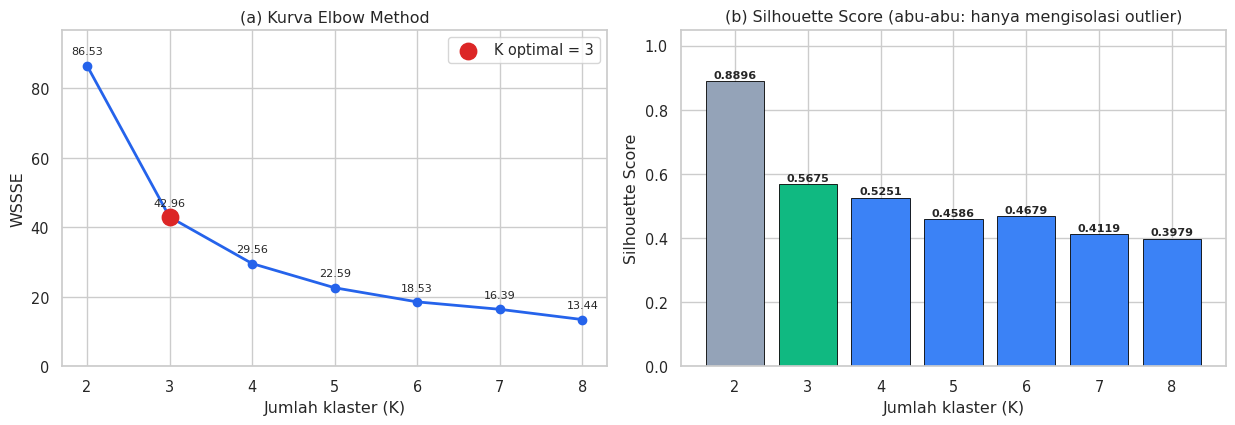

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
ax.plot(eval_df["k"], eval_df["wssse"], "-o", color="#2563EB", lw=2)
for _, r in eval_df.iterrows():
    ax.annotate(f"{r['wssse']:.2f}", (r["k"], r["wssse"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
opt = eval_df[eval_df["k"] == optimal_k].iloc[0]
ax.scatter([opt["k"]], [opt["wssse"]], s=140, color="#DC2626", zorder=5, label=f"K optimal = {optimal_k}")
ax.set_xlabel("Jumlah klaster (K)"); ax.set_ylabel("WSSSE"); ax.set_title("(a) Kurva Elbow Method")
ax.set_xticks(K_RANGE); ax.set_ylim(0, eval_df["wssse"].max() * 1.12); ax.legend()

ax = axes[1]
colors = ["#94A3B8" if m < 2 else "#10B981" if k == optimal_k else "#3B82F6"
          for k, m in zip(eval_df["k"], eval_df["klaster_multi_state"])]
bars = ax.bar(eval_df["k"].astype(str), eval_df["silhouette"], color=colors, edgecolor="black", lw=0.6)
for b, v in zip(bars, eval_df["silhouette"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.4f}", ha="center", fontsize=8, fontweight="bold")
ax.set_xlabel("Jumlah klaster (K)"); ax.set_ylabel("Silhouette Score"); ax.set_ylim(0, 1.05)
ax.set_title("(b) Silhouette Score (abu-abu: hanya mengisolasi outlier)")
plt.tight_layout(); plt.show()

## 5.4 Mengapa K = 3?

1. **K = 2 bukan solusi yang berguna.** Model hanya memisahkan São Paulo sebagai *outlier* tunggal dari 26 negara bagian lain. Silhouette Score-nya tinggi, tetapi itu akibat satu klaster *singleton*, bukan karena segmentasi yang bermakna.
2. **K = 3 memberi penurunan WSSSE terbesar** setelah K = 2 dan menghasilkan dua klaster *multi-state* yang kohesif; pada eksekusi acuan, skor gabungannya (jarak siku 0,3037 + Silhouette 0,5675 = 0,8712) lebih tinggi daripada K = 4 (0,3155 + 0,5251 = 0,8406).
3. **K ≥ 4 hanya memecah klaster sekunder** menjadi sub-kelompok kecil dengan Silhouette Score yang lebih rendah, sehingga interpretasi bisnis menjadi sulit (fragmentasi berlebih pada hanya 27 observasi).
4. **Interpretabilitas.** Tiga zona (pusat megamarket, pasar sekunder, wilayah perifer) selaras dengan struktur logistik Brasil dan mudah diterjemahkan menjadi strategi yang berbeda.

> **Catatan metodologis.** K-Means bergantung pada inisialisasi acak dan dapat berhenti pada optimum lokal (pada data ini, beberapa *seed* menghasilkan partisi tiga klaster dengan WSSSE jauh lebih besar). Nilai acuan laporan di bawah dihasilkan dengan `seed=1`. Sel berikut membandingkan hasil eksekusi Anda dengan nilai acuan tersebut.

In [15]:
REFERENSI_LAPORAN = {   # k: (WSSSE, Silhouette) pada Tabel 3 laporan akhir (seed=1)
    2: (86.5273, 0.8896), 3: (42.9592, 0.5675), 4: (29.5565, 0.5251), 5: (22.5875, 0.4586),
    6: (18.5277, 0.4679), 7: (16.3881, 0.4119), 8: (13.4401, 0.3979),
}
cek = eval_df[["k", "wssse", "silhouette"]].copy()
cek["wssse_laporan"] = cek["k"].map(lambda k: REFERENSI_LAPORAN[k][0])
cek["silhouette_laporan"] = cek["k"].map(lambda k: REFERENSI_LAPORAN[k][1])
cek["sesuai"] = [("ya" if abs(a - b) < 0.01 and abs(c - d) < 0.005 else "berbeda")
                 for a, b, c, d in zip(cek["wssse"], cek["wssse_laporan"], cek["silhouette"], cek["silhouette_laporan"])]
display(cek.style.format({"wssse": "{:.4f}", "wssse_laporan": "{:.4f}", "silhouette": "{:.4f}", "silhouette_laporan": "{:.4f}"}))
if (cek["sesuai"] == "ya").all():
    print("Seluruh nilai sesuai dengan Tabel 3 laporan.")
else:
    print("Ada nilai yang berbeda dari Tabel 3 laporan (mis. beda versi Spark atau seed). "
          "Samakan tabel laporan dengan keluaran notebook ini sebelum dikumpulkan.")

,k,wssse,silhouette,wssse_laporan,silhouette_laporan,sesuai
0,2,86.5273,0.8896,86.5273,0.8896,ya
1,3,42.9592,0.5675,42.9592,0.5675,ya
2,4,29.5565,0.5251,29.5565,0.5251,ya
3,5,22.5875,0.4586,22.5875,0.4586,ya
4,6,18.5277,0.4679,18.5277,0.4679,ya
5,7,16.3881,0.4119,16.3881,0.4119,ya
6,8,13.4401,0.3979,13.4401,0.3979,ya


Seluruh nilai sesuai dengan Tabel 3 laporan.


---
# BAB 6. PROFILING DAN INTERPRETASI KLASTER WILAYAH

## 6.1 Model Final dan Penomoran Klaster

Model final adalah model K-Means dengan K optimal pada Bab 5. Karena nomor klaster mentah dari K-Means bersifat acak, klaster **diurutkan ulang** berdasarkan rata-rata jumlah pelanggan per negara bagian (terbesar → terkecil) menggunakan *window function* Spark SQL, sehingga **Cluster 0 = pusat megamarket**, klaster terakhir = wilayah perifer, dan klaster di antaranya = pasar sekunder. Nama dan rekomendasi strategi mengikuti urutan tersebut.

In [16]:
model_final = models_by_k[optimal_k]
df_clustered_raw = model_final.transform(df_scaled).withColumnRenamed("prediction", "raw_cluster")
df_clustered_raw.createOrReplaceTempView("raw_clustered_states")

df_cluster_mapping = spark.sql("""
    WITH raw_stats AS (
        SELECT raw_cluster, AVG(total_customers) AS mean_cust, AVG(avg_freight_value) AS mean_freight
        FROM raw_clustered_states GROUP BY raw_cluster
    ),
    ranked AS (
        SELECT raw_cluster,
               CAST(DENSE_RANK() OVER (ORDER BY mean_cust DESC) - 1 AS INT) AS ordered_cluster,
               COUNT(*) OVER () AS total_k
        FROM raw_stats
    )
    SELECT raw_cluster,
           ordered_cluster AS cluster,
           CASE WHEN ordered_cluster = 0 THEN 'Pusat Megamarket'
                WHEN ordered_cluster = total_k - 1 THEN 'Wilayah Perifer Logistik Tinggi'
                ELSE 'Pasar Sekunder Berkembang' END AS cluster_name,
           CASE WHEN ordered_cluster = 0 THEN 'Optimalisasi pengiriman instan/same-day, otomatisasi gudang pusat, dan retensi pelanggan frekuensi tinggi.'
                WHEN ordered_cluster = total_k - 1 THEN 'Subsidi ongkos kirim bersyarat (minimum nilai pesanan), konsolidasi kargo regional, dan kemitraan kurir lokal.'
                ELSE 'Penempatan stok kategori populer di hub distribusi regional (Tier-2) dan promosi bundling untuk menaikkan nilai pesanan.' END AS strategy_recommendation
    FROM ranked
""")
df_cluster_mapping.createOrReplaceTempView("cluster_mapping")

df_state_clusters = spark.sql("""
    WITH state_cities AS (
        SELECT customer_state AS state_code, CAST(COUNT(DISTINCT customer_city) AS INT) AS total_cities
        FROM customers GROUP BY customer_state
    ),
    state_sellers AS (
        SELECT seller_state AS state_code, CAST(COUNT(DISTINCT seller_id) AS INT) AS total_sellers
        FROM sellers GROUP BY seller_state
    )
    SELECT r.customer_state, m.cluster, m.cluster_name,
           ROUND(r.total_customers, 0) AS total_customers,
           COALESCE(sc.total_cities, 0) AS total_cities,
           COALESCE(ss.total_sellers, 0) AS total_sellers,
           ROUND(r.total_orders, 0) AS total_orders,
           ROUND(r.total_revenue, 2) AS total_revenue,
           ROUND(r.avg_order_value, 2) AS avg_order_value,
           ROUND(r.total_items, 0) AS total_items,
           ROUND(r.avg_items_per_order, 2) AS avg_items_per_order,
           ROUND(r.avg_freight_value, 2) AS avg_freight_value,
           ROUND(r.freight_to_price_pct, 2) AS freight_to_price_pct,
           ROUND(r.avg_delivery_days, 2) AS avg_delivery_days,
           ROUND(r.avg_review_score, 2) AS avg_review_score,
           r.lat, r.lng
    FROM raw_clustered_states r
    JOIN cluster_mapping m ON r.raw_cluster = m.raw_cluster
    LEFT JOIN state_cities sc ON r.customer_state = sc.state_code
    LEFT JOIN state_sellers ss ON r.customer_state = ss.state_code
    ORDER BY m.cluster ASC, r.total_revenue DESC
""").cache()
df_state_clusters.createOrReplaceTempView("cluster_state_view")

pdf_clusters = df_state_clusters.toPandas()
display(pdf_clusters[["customer_state", "cluster", "cluster_name", "total_customers", "total_cities", "total_sellers",
                      "total_orders", "total_revenue", "avg_order_value", "avg_freight_value", "avg_review_score"]]
        .style.format({"total_customers": "{:,.0f}", "total_orders": "{:,.0f}", "total_revenue": "{:,.2f}"}))

,customer_state,cluster,cluster_name,total_customers,total_cities,total_sellers,total_orders,total_revenue,avg_order_value,avg_freight_value,avg_review_score
0,SP,0,Pusat Megamarket,"40,302",629,1849,"40,501","5,770,266.19",142.480000,15.270000,4.250000
1,RJ,1,Pasar Sekunder Berkembang,"12,384",149,171,"12,350","2,055,690.45",166.450000,21.100000,3.970000
2,MG,1,Pasar Sekunder Berkembang,"11,259",745,244,"11,354","1,819,277.61",160.230000,20.800000,4.190000
3,RS,1,Pasar Sekunder Berkembang,"5,277",379,129,"5,345","861,802.40",161.240000,21.830000,4.190000
4,PR,1,Pasar Sekunder Berkembang,"4,882",364,349,"4,923","781,919.55",158.830000,20.410000,4.240000
5,SC,1,Pasar Sekunder Berkembang,"3,534",240,190,"3,546","595,208.40",167.850000,21.800000,4.130000
6,BA,1,Pasar Sekunder Berkembang,"3,277",353,19,"3,256","591,270.60",181.590000,26.360000,3.930000
7,DF,1,Pasar Sekunder Berkembang,"2,075",6,30,"2,080","346,146.17",166.420000,21.360000,4.130000
8,GO,1,Pasar Sekunder Berkembang,"1,952",178,40,"1,957","334,294.22",170.820000,23.030000,4.100000
9,ES,1,Pasar Sekunder Berkembang,"1,964",95,23,"1,995","317,682.65",159.240000,22.150000,4.080000


## 6.2 Profil Karakteristik Tiap Klaster (RQ2)

In [17]:
df_cluster_summary = spark.sql("""
    SELECT cs.cluster, cs.cluster_name,
           FIRST(cm.strategy_recommendation) AS strategy_recommendation,
           CAST(COUNT(cs.customer_state) AS INT) AS total_states,
           CONCAT_WS(', ', COLLECT_LIST(cs.customer_state)) AS states_list,
           ROUND(SUM(cs.total_customers), 0) AS sum_customers,
           ROUND(AVG(cs.total_cities), 1) AS avg_cities_per_state,
           CAST(SUM(cs.total_sellers) AS INT) AS sum_sellers,
           ROUND(SUM(cs.total_orders), 0) AS sum_orders,
           ROUND(AVG(cs.total_orders), 1) AS avg_orders_per_state,
           ROUND(SUM(cs.total_revenue), 2) AS sum_revenue,
           ROUND(AVG(cs.total_revenue), 2) AS avg_revenue_per_state,
           ROUND(AVG(cs.avg_order_value), 2) AS avg_order_ticket_size,
           ROUND(AVG(cs.avg_freight_value), 2) AS avg_freight,
           ROUND(AVG(cs.freight_to_price_pct), 2) AS avg_freight_ratio_pct,
           ROUND(AVG(cs.avg_delivery_days), 2) AS avg_delivery_days,
           ROUND(AVG(cs.avg_review_score), 2) AS avg_satisfaction
    FROM cluster_state_view cs
    JOIN cluster_mapping cm ON cs.cluster = cm.cluster
    GROUP BY cs.cluster, cs.cluster_name
    ORDER BY cs.cluster
""")
pdf_summary = df_cluster_summary.toPandas()
display(pdf_summary.drop(columns=["strategy_recommendation"]).set_index("cluster").T)

cluster,0,1,2
cluster_name,Pusat Megamarket,Pasar Sekunder Berkembang,Wilayah Perifer Logistik Tinggi
total_states,1,13,13
states_list,SP,"AM, MS, MT, PE, ES, GO, DF, BA, SC, PR, RS, MG...","RR, AP, AC, RO, TO, SE, AL, RN, PI, PB, MA, PA..."
sum_customers,"40,302.0000","49,926.0000","5,908.0000"
avg_cities_per_state,629.0000,218.0000,65.2000
sum_sellers,1849,1214,32
sum_orders,"40,501.0000","50,131.0000","5,846.0000"
avg_orders_per_state,"40,501.0000","3,856.2000",449.7000
sum_revenue,"5,770,266.1900","8,355,826.0800","1,296,369.5000"
avg_revenue_per_state,"5,770,266.1900","642,755.8500","99,720.7300"


## 6.3 RQ4 — Perbandingan Wilayah Berkepadatan Tinggi, Menengah, dan Rendah

Tingkat kepadatan diturunkan dari urutan klaster (Cluster 0 = tinggi, tengah = menengah, terakhir = rendah). Perbandingan bersifat **deskriptif**; belum ada uji statistik karena unit analisisnya hanya 27 negara bagian.

In [18]:
df_density = spark.sql("""
    WITH national_totals AS (
        SELECT SUM(total_customers) AS nat_customers, SUM(total_orders) AS nat_orders, SUM(total_revenue) AS nat_revenue
        FROM cluster_state_view
    )
    SELECT cs.cluster,
           CASE WHEN cs.cluster = 0 THEN 'Kepadatan Tinggi (Pusat Megamarket)'
                WHEN cs.cluster = 1 THEN 'Kepadatan Menengah (Pasar Sekunder)'
                ELSE 'Kepadatan Rendah (Wilayah Perifer)' END AS density_tier,
           CAST(COUNT(cs.customer_state) AS INT) AS total_states,
           ROUND(SUM(cs.total_customers) * 100.0 / MAX(nt.nat_customers), 2) AS share_customers_pct,
           ROUND(SUM(cs.total_orders) * 100.0 / MAX(nt.nat_orders), 2) AS share_orders_pct,
           ROUND(SUM(cs.total_revenue) * 100.0 / MAX(nt.nat_revenue), 2) AS share_revenue_pct,
           CAST(SUM(cs.total_sellers) AS INT) AS total_sellers,
           ROUND(AVG(cs.avg_order_value), 2) AS avg_order_value,
           ROUND(AVG(cs.avg_freight_value), 2) AS avg_freight_value,
           ROUND(AVG(cs.freight_to_price_pct), 2) AS freight_to_price_pct,
           ROUND(AVG(cs.avg_delivery_days), 2) AS avg_delivery_days,
           ROUND(AVG(cs.avg_review_score), 2) AS avg_review_score
    FROM cluster_state_view cs CROSS JOIN national_totals nt
    GROUP BY cs.cluster
    ORDER BY cs.cluster
""")
pdf_density = df_density.toPandas()
display(pdf_density.set_index("cluster").T)

# Selisih Cluster terakhir (kepadatan rendah) terhadap Cluster 0 (kepadatan tinggi)
lo, hi = pdf_density.iloc[-1], pdf_density.iloc[0]
print(f"Nilai pesanan rata-rata : {lo.avg_order_value / hi.avg_order_value - 1:+.2%} dibanding kepadatan tinggi")
print(f"Ongkos kirim rata-rata  : {lo.avg_freight_value / hi.avg_freight_value - 1:+.2%} dibanding kepadatan tinggi")
print(f"Waktu pengiriman        : {lo.avg_delivery_days:.2f} hari vs {hi.avg_delivery_days:.2f} hari")

cluster,0,1,2
density_tier,Kepadatan Tinggi (Pusat Megamarket),Kepadatan Menengah (Pasar Sekunder),Kepadatan Rendah (Wilayah Perifer)
total_states,1,13,13
share_customers_pct,41.9200,51.9300,6.1500
share_orders_pct,41.9800,51.9600,6.0600
share_revenue_pct,37.4100,54.1800,8.4100
total_sellers,1849,1214,32
avg_order_value,142.4800,174.8900,226.5900
avg_freight_value,15.2700,24.3900,38.2300
freight_to_price_pct,13.8500,18.6500,23.2500
avg_delivery_days,8.7000,16.2300,21.9800


Nilai pesanan rata-rata : +59.03% dibanding kepadatan tinggi
Ongkos kirim rata-rata  : +150.36% dibanding kepadatan tinggi
Waktu pengiriman        : 21.98 hari vs 8.70 hari


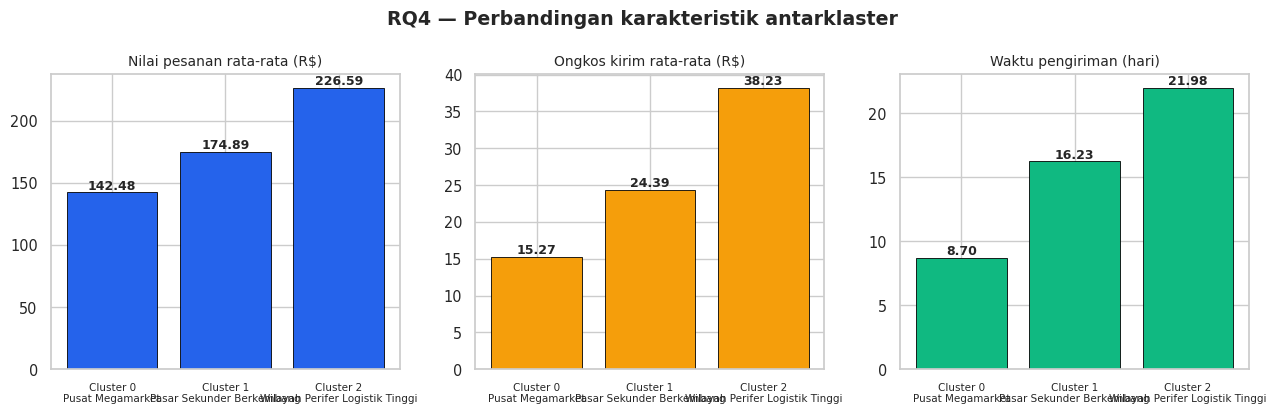

In [19]:
labels = [f"Cluster {c}\n{n}" for c, n in zip(pdf_summary["cluster"], pdf_summary["cluster_name"])]
metrics = [("avg_order_ticket_size", "Nilai pesanan rata-rata (R$)", "#2563EB"),
           ("avg_freight", "Ongkos kirim rata-rata (R$)", "#F59E0B"),
           ("avg_delivery_days", "Waktu pengiriman (hari)", "#10B981")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (col, title, color) in zip(axes, metrics):
    bars = ax.bar(range(len(pdf_summary)), pdf_summary[col], color=color, edgecolor="black", lw=0.6)
    for b, v in zip(bars, pdf_summary[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(range(len(pdf_summary))); ax.set_xticklabels(labels, fontsize=7.5)
    ax.set_title(title, fontsize=10)
fig.suptitle("RQ4 — Perbandingan karakteristik antarklaster", fontweight="bold")
plt.tight_layout(); plt.show()

## 6.4 Peta Sebaran Klaster

Peta menggunakan koordinat rata-rata geolokasi tiap negara bagian. Sel ini bersifat opsional dan memerlukan `plotly`.

In [20]:
try:
    import plotly.express as px
    pm = pdf_clusters.dropna(subset=["lat", "lng"]).assign(cluster_label=lambda d: "Cluster " + d["cluster"].astype(str) + " — " + d["cluster_name"])
    fig = px.scatter_geo(pm, lat="lat", lon="lng", color="cluster_label", size="total_customers", hover_name="customer_state",
                         hover_data={"total_customers": ":,.0f", "avg_freight_value": ":.2f", "lat": False, "lng": False},
                         size_max=45, title="Sebaran klaster negara bagian Brasil (ukuran gelembung = jumlah pelanggan unik)")
    fig.update_geos(scope="south america", showcountries=True, fitbounds="locations")
    fig.show()
except ImportError:
    print("plotly belum terpasang; lewati sel ini atau jalankan: pip install plotly")

---
# BAB 7. ANALISIS KATEGORI PRODUK DOMINAN PER KLASTER (RQ3)

Hasil klasterisasi digabungkan dengan item pesanan *delivered* dan nama kategori produk (diterjemahkan ke bahasa Inggris melalui `category_translation`). Peringkat dihitung berdasarkan jumlah unit terjual pada tiap klaster; pangsa dihitung terhadap total item klaster tersebut.

In [21]:
df_cluster_products = spark.sql("""
    WITH cluster_totals AS (
        SELECT cs.cluster, COUNT(oi.order_item_id) AS cluster_total_items
        FROM cluster_state_view cs
        JOIN customers c ON cs.customer_state = c.customer_state
        JOIN orders o ON c.customer_id = o.customer_id AND o.order_status = 'delivered'
        JOIN order_items oi ON o.order_id = oi.order_id
        GROUP BY cs.cluster
    ),
    state_prod AS (
        SELECT cs.cluster, cs.cluster_name,
               COALESCE(ct.product_category_name_english, pr.product_category_name, 'unclassified') AS category_name,
               COUNT(oi.order_item_id) AS total_sold,
               ROUND(SUM(oi.price), 2) AS total_revenue,
               ROUND(AVG(oi.price), 2) AS avg_price,
               ROUND(AVG(oi.freight_value), 2) AS avg_freight,
               ROW_NUMBER() OVER (PARTITION BY cs.cluster ORDER BY COUNT(oi.order_item_id) DESC) AS rank
        FROM cluster_state_view cs
        JOIN customers c ON cs.customer_state = c.customer_state
        JOIN orders o ON c.customer_id = o.customer_id AND o.order_status = 'delivered'
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products pr ON oi.product_id = pr.product_id
        LEFT JOIN category_translation ct ON pr.product_category_name = ct.product_category_name
        GROUP BY cs.cluster, cs.cluster_name,
                 COALESCE(ct.product_category_name_english, pr.product_category_name, 'unclassified')
    )
    SELECT sp.cluster, sp.cluster_name, CAST(sp.rank AS INT) AS rank, sp.category_name, sp.total_sold,
           ROUND(sp.total_sold * 100.0 / ct.cluster_total_items, 2) AS pct_of_cluster_items,
           sp.total_revenue, sp.avg_price, sp.avg_freight
    FROM state_prod sp JOIN cluster_totals ct ON sp.cluster = ct.cluster
    WHERE sp.rank <= 5
    ORDER BY sp.cluster, sp.rank
""")
pdf_products = df_cluster_products.toPandas()
display(pdf_products.style.format({"total_sold": "{:,.0f}", "pct_of_cluster_items": "{:.2f}",
                                   "total_revenue": "{:,.2f}", "avg_price": "{:,.2f}", "avg_freight": "{:,.2f}"}))

,cluster,cluster_name,rank,category_name,total_sold,pct_of_cluster_items,total_revenue,avg_price,avg_freight
0,0,Pusat Megamarket,1,bed_bath_table,"5,157",11.10,"472,238.07",91.57,14.90
1,0,Pusat Megamarket,2,health_beauty,"4,125",8.88,"453,916.48",110.04,13.66
2,0,Pusat Megamarket,3,sports_leisure,"3,576",7.70,"375,044.87",104.88,14.87
3,0,Pusat Megamarket,4,furniture_decor,"3,454",7.44,"277,926.26",80.47,16.03
4,0,Pusat Megamarket,5,housewares,"3,184",6.85,"269,656.60",84.69,16.88
5,1,Pasar Sekunder Berkembang,1,bed_bath_table,"5,473",9.56,"518,008.64",94.65,20.69
6,1,Pasar Sekunder Berkembang,2,health_beauty,"4,615",8.06,"635,589.81",137.72,20.94
7,1,Pasar Sekunder Berkembang,3,sports_leisure,"4,399",7.69,"516,074.29",117.32,21.23
8,1,Pasar Sekunder Berkembang,4,furniture_decor,"4,315",7.54,"389,671.56",90.31,22.65
9,1,Pasar Sekunder Berkembang,5,computers_accessories,"4,048",7.07,"476,235.43",117.65,20.47


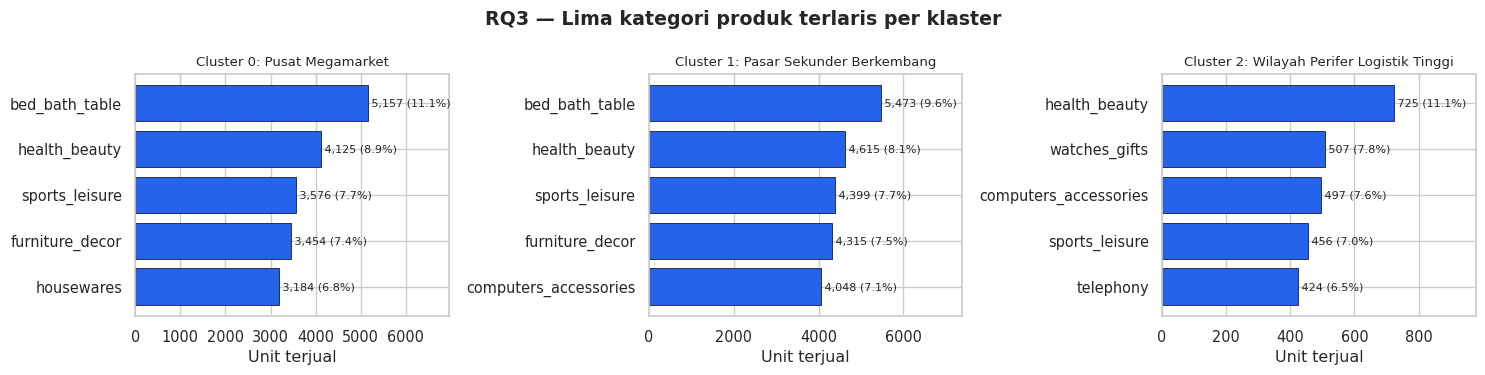

,rank,category_name,avg_price,avg_freight
10,1,health_beauty,198.1000,35.8400
11,2,watches_gifts,233.4600,30.4700
12,3,computers_accessories,143.7500,32.0000
13,4,sports_leisure,139.7700,36.9100
14,5,telephony,97.4700,27.0600


In [22]:
clusters = sorted(pdf_products["cluster"].unique())
fig, axes = plt.subplots(1, len(clusters), figsize=(5 * len(clusters), 3.8), sharex=False)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, clusters):
    d = pdf_products[pdf_products["cluster"] == c].sort_values("total_sold")
    ax.barh(d["category_name"], d["total_sold"], color="#2563EB", edgecolor="black", lw=0.5)
    for y, (v, p) in enumerate(zip(d["total_sold"], d["pct_of_cluster_items"])):
        ax.text(v, y, f" {v:,.0f} ({p:.1f}%)", va="center", fontsize=8)
    ax.set_title(f"Cluster {c}: {d['cluster_name'].iloc[0]}", fontsize=9.5)
    ax.set_xlim(0, d["total_sold"].max() * 1.35); ax.set_xlabel("Unit terjual")
fig.suptitle("RQ3 — Lima kategori produk terlaris per klaster", fontweight="bold")
plt.tight_layout(); plt.show()

# Harga rata-rata kategori dominan pada klaster perifer (produk bernilai tinggi dan ringkas)
display(pdf_products[pdf_products["cluster"] == clusters[-1]][["rank", "category_name", "avg_price", "avg_freight"]])

**Interpretasi.** Klaster pusat dan klaster sekunder didominasi barang rumah tangga berdimensi besar (`bed_bath_table`, `furniture_decor`, `housewares`), sedangkan klaster perifer didominasi produk bernilai tinggi dan relatif ringkas (`health_beauty`, `watches_gifts`, `computers_accessories`, `telephony`) dengan harga rata-rata per unit jauh lebih tinggi. Pola ini konsisten dengan ongkos kirim tinggi di wilayah perifer: pelanggan cenderung membeli barang yang nilainya sepadan dengan ongkos kirim. Kesimpulan ini bersifat deskriptif.

---
# BAB 8. IMPLIKASI MANAJERIAL DAN REKOMENDASI BISNIS STRATEGIS

## 8.1 Temuan Utama

1. **Ketimpangan spasial penjual dan pembeli.** São Paulo menyerap sekitar 42% pelanggan unik dan memiliki sekitar 60% penjual nasional, sedangkan klaster perifer hanya memiliki sebagian kecil penjual. Akibatnya ongkos kirim dan waktu pengiriman klaster perifer jauh lebih tinggi.
2. **Paradoks ongkos kirim dan nilai pesanan (RQ4).** Wilayah berkepadatan rendah memiliki nilai pesanan rata-rata tertinggi meskipun ongkos kirimnya paling mahal; diduga pelanggan hanya membeli barang bernilai tinggi agar sepadan dengan ongkos kirim.
3. **Pergeseran preferensi kategori (RQ3).** Barang rumah tangga dominan di pusat dan pasar sekunder, produk bernilai tinggi dan ringkas dominan di wilayah perifer.

## 8.2 Rekomendasi

| Pemangku kepentingan | Cluster 0 — Pusat Megamarket | Cluster 1 — Pasar Sekunder | Cluster 2 — Wilayah Perifer |
|---|---|---|---|
| **Tim Pemasaran** | Promosi pengiriman *same-day*, *cross-selling* kategori rumah tangga | Promosi *bundling* untuk menaikkan nilai pesanan | Voucher subsidi ongkir bersyarat (mis. minimum transaksi R$ 200) untuk `health_beauty`, `watches_gifts`, elektronik |
| **Tim Inventaris / Rantai Pasok** | Stok penyangga furnitur dan rumah tangga di gudang Tenggara–Selatan | Stok kategori populer di hub regional (Tier-2) | Stok produk bernilai tinggi dan ringkas di hub regional Timur Laut (mis. Recife, Fortaleza, Salvador) |
| **Tim Operasional** | Otomatisasi gudang pusat | Konsolidasi kargo regional | *Seller onboarding* di Timur Laut dan Utara untuk menurunkan waktu kirim (target < 14 hari) |

## 8.3 Keterbatasan

- Klasterisasi hanya memakai **27 observasi** (negara bagian) dengan fitur agregat transaksi dan logistik; **belum ada data demografi eksternal** (mis. penduduk atau pendapatan per kapita dari IBGE).
- Perbandingan antarklaster **deskriptif**, tanpa uji statistik.
- K-Means sensitif terhadap inisialisasi; hasil acuan dihasilkan dengan `seed=1`.
- Teks ulasan (data tidak terstruktur) belum dianalisis.

## 8.4 Ekspor Hasil untuk Dashboard Streamlit

Tabel hasil diekspor ke folder `output/` dalam format CSV agar dapat dibaca oleh `dashboard.py` atau dianalisis ulang tanpa menjalankan Spark.

In [23]:
os.makedirs("output", exist_ok=True)
exports = {
    "analytics_kmeans_eval.csv": eval_df,
    "analytics_state_clusters.csv": pdf_clusters,
    "analytics_cluster_summary.csv": pdf_summary,
    "analytics_cluster_products.csv": pdf_products,
    "analytics_density_comparison.csv": pdf_density,
    "analytics_top_cities.csv": df_cities,
}
for fname, frame in exports.items():
    frame.to_csv(os.path.join("output", fname), index=False)
    print(f"✓ output/{fname:<34} {len(frame):>3} baris")

✓ output/analytics_kmeans_eval.csv            7 baris
✓ output/analytics_state_clusters.csv        27 baris
✓ output/analytics_cluster_summary.csv        3 baris
✓ output/analytics_cluster_products.csv      15 baris
✓ output/analytics_density_comparison.csv     3 baris
✓ output/analytics_top_cities.csv            25 baris


## 8.5 Penutup

Notebook ini menunjukkan alur lengkap segmentasi wilayah Olist: pemuatan sembilan tabel, pra-agregasi anti *join fan-out*, rekayasa tujuh fitur wilayah, evaluasi K = 2–8 dengan Elbow Method dan Silhouette Score, pembentukan tiga klaster wilayah, serta analisis kategori produk dan rekomendasi strategi. Arsitektur *end-to-end* penuh (Kafka → PostgreSQL → Spark → Streamlit) tersedia pada berkas `producer.py`, `consumer.py`, `eda_spark.py`, dan `dashboard.py` di repositori proyek.

**Referensi kunci:** Zaharia et al. (2016) untuk Apache Spark; Meng et al. (2016) untuk MLlib; Rousseeuw (1987) untuk Silhouette; Satopaa et al. (2011) untuk titik siku Kneedle; Arthur & Vassilvitskii (2007) untuk inisialisasi k-means++ (rujukan lengkap pada Daftar Pustaka laporan akhir).

In [24]:
# spark.stop()   # hapus tanda komentar untuk menghentikan Spark setelah selesai